<a href="https://colab.research.google.com/github/Shivamthakur7500/FireWatchNet/blob/main/Vision_Transformer_(ViT).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install rasterio

import rasterio
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/FireWatchNet")
raw_dir = project_dir / "Data/raw/fire/satellite/FireWatchNet_Data"

tile_path = sorted(raw_dir.glob("*.tif"))[0]

with rasterio.open(tile_path) as src:
    print("File:", tile_path.name)
    print("Width:", src.width, "pixels")
    print("Height:", src.height, "pixels")
    print("Number of bands:", src.count)
    print("Band data types:", src.dtypes)
    print("Coordinate system:", src.crs)
    print("No-data value:", src.nodata)
    print("Pixel resolution:", src.res)
    print("Band descriptions:", src.descriptions)

    # Read only a small sample, not the full image
    sample = src.read(
        window=((0, min(256, src.height)),
                (0, min(256, src.width))),
        masked=True
    )

    print("\nSample shape (bands, height, width):", sample.shape)
    print("Sample minimum:", sample.min())
    print("Sample maximum:", sample.max())
    print("Sample masked pixels:", sample.mask.sum())

File: S2_forest_only-0000000000-0000000000.tif
Width: 9472 pixels
Height: 9472 pixels
Number of bands: 6
Band data types: ('float64', 'float64', 'float64', 'float64', 'float64', 'float64')
Coordinate system: EPSG:4326
No-data value: None
Pixel resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Band descriptions: ('B4', 'B3', 'B2', 'B8', 'B11', 'B12')

Sample shape (bands, height, width): (6, 256, 256)
Sample minimum: nan
Sample maximum: nan
Sample masked pixels: 0


In [ ]:

import rasterio
import numpy as np
from pathlib import Path

raw_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/Data/raw/fire/"
    "satellite/FireWatchNet_Data"
)

tiles = sorted(list(raw_dir.glob("*.tif")) +
               list(raw_dir.glob("*.tiff")))

patch_size = 224
valid_threshold = 0.80

total_patches = 0
total_usable = 0

print(f"{'Tile':<48} {'Patches':>9} {'Usable':>9} {'Usable %':>10}")
print("-" * 80)

for tile_path in tiles:
    tile_patches = 0
    tile_usable = 0

    with rasterio.open(tile_path) as src:
        for row in range(0, src.height - patch_size + 1, patch_size):
            for col in range(0, src.width - patch_size + 1, patch_size):
                window = rasterio.windows.Window(
                    col, row, patch_size, patch_size
                )
                band = src.read(1, window=window)
                valid_fraction = np.isfinite(band).mean()

                tile_patches += 1
                if valid_fraction >= valid_threshold:
                    tile_usable += 1

    total_patches += tile_patches
    total_usable += tile_usable

    usable_pct = 100 * tile_usable / tile_patches if tile_patches else 0
    print(f"{tile_path.name:<48} {tile_patches:>9} "
          f"{tile_usable:>9} {usable_pct:>9.1f}%")

print("-" * 80)
print("Total tiles:", len(tiles))
print("Total complete patches:", total_patches)
print("Total patches meeting threshold:", total_usable)
print("Overall usable percentage:",
      f"{100 * total_usable / total_patches:.1f}%"
      if total_patches else "N/A")


Tile                                               Patches    Usable   Usable %
--------------------------------------------------------------------------------
S2_forest_only-0000000000-0000000000.tif              1764       346      19.6%
S2_forest_only-0000000000-0000009472.tif              1764         7       0.4%
S2_forest_only-0000000000-0000018944.tif              1764         0       0.0%
S2_forest_only-0000000000-0000028416.tif               924         0       0.0%
S2_forest_only-0000009472-0000000000.tif              1764       946      53.6%
S2_forest_only-0000009472-0000009472.tif              1764       706      40.0%
S2_forest_only-0000009472-0000018944.tif              1764       273      15.5%
S2_forest_only-0000009472-0000028416.tif               924        11       1.2%
S2_forest_only-0000018944-0000000000.tif              1680       243      14.5%
S2_forest_only-0000018944-0000009472.tif              1680       780      46.4%
S2_forest_only-0000018944-0000018944.ti

Tile: S2_forest_only-0000000000-0000000000.tif
Patch row/column: 224 224
Valid pixels: 90.23%


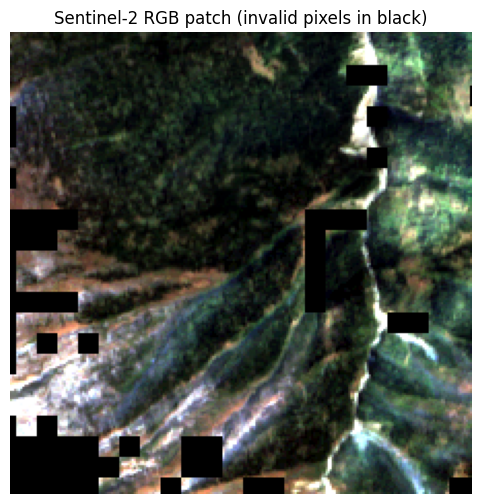

In [ ]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

raw_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/Data/raw/fire/"
    "satellite/FireWatchNet_Data"
)

patch_size = 224
threshold = 0.80
found = False

for tile_path in sorted(raw_dir.glob("*.tif")):
    with rasterio.open(tile_path) as src:
        for row in range(0, src.height - patch_size + 1, patch_size):
            for col in range(0, src.width - patch_size + 1, patch_size):
                window = rasterio.windows.Window(
                    col, row, patch_size, patch_size
                )
                patch = src.read(window=window).astype(np.float32)

                valid = np.isfinite(patch).all(axis=0)
                if valid.mean() >= threshold:
                    found = True
                    break
            if found:
                break
    if found:
        break

if not found:
    print("No patch met the valid-pixel threshold.")
else:
    print("Tile:", tile_path.name)
    print("Patch row/column:", row, col)
    print("Valid pixels:", f"{valid.mean() * 100:.2f}%")

    # Bands are ordered B4, B3, B2, B8, B11, B12.
    # Display only RGB, using valid pixels to estimate contrast.
    rgb = np.moveaxis(patch[[0, 1, 2]], 0, -1)
    rgb_valid = np.isfinite(rgb).all(axis=2)

    rgb_display = np.zeros_like(rgb)
    for channel in range(3):
        values = rgb[:, :, channel][rgb_valid]
        low, high = np.percentile(values, [2, 98])
        rgb_display[:, :, channel] = np.clip(
            (rgb[:, :, channel] - low) / max(high - low, 1e-6),
            0, 1
        )

    rgb_display[~rgb_valid] = 0

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb_display)
    plt.title("Sentinel-2 RGB patch (invalid pixels in black)")
    plt.axis("off")
    plt.show()

In [ ]:

import rasterio
from pathlib import Path

raw_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/Data/raw/fire/"
    "satellite/FireWatchNet_Data"
)

tile_path = raw_dir / "S2_forest_only-0000000000-0000000000.tif"

patch_row = 224
patch_col = 224
patch_size = 224

with rasterio.open(tile_path) as src:
    # Center of the selected image patch
    center_row = patch_row + patch_size / 2
    center_col = patch_col + patch_size / 2

    lon, lat = src.xy(center_row, center_col)

    # Geographic extent of the patch
    left, top = src.xy(patch_row, patch_col)
    right, bottom = src.xy(
        patch_row + patch_size,
        patch_col + patch_size
    )

    print("Tile:", tile_path.name)
    print(f"Patch center latitude: {lat:.6f}")
    print(f"Patch center longitude: {lon:.6f}")
    print(f"Approximate latitude range: {min(top, bottom):.6f} to {max(top, bottom):.6f}")
    print(f"Approximate longitude range: {min(left, right):.6f} to {max(left, right):.6f}")

Tile: S2_forest_only-0000000000-0000000000.tif
Patch center latitude: 31.478540
Patch center longitude: 78.030226
Approximate latitude range: 31.468478 to 31.488601
Approximate longitude range: 78.020165 to 78.040287


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

fire_path = Path(
    "/content/drive/MyDrive/FireWatchNet/"
    "Data/processed/VIIRS/VIIRS_Uttarakhand_2023_2024.csv"
)

patch_lat = 31.478540
patch_lon = 78.030226

# Search radius for this initial diagnostic (not a final label rule)
radius_km = 2.0

fires = pd.read_csv(fire_path)

print("Columns:", fires.columns.tolist())
print("Total fire detections:", len(fires))

# Approximate distance in km for a small area
lat_km = (fires["latitude"] - patch_lat) * 111.0
lon_km = (fires["longitude"] - patch_lon) * (
    111.0 * np.cos(np.radians(patch_lat))
)
distance_km = np.sqrt(lat_km**2 + lon_km**2)

nearby = fires[distance_km <= radius_km].copy()

print(f"\nDetections within {radius_km} km:", len(nearby))

if len(nearby):
    print("\nDate range:",
          nearby["acq_date"].min(), "to", nearby["acq_date"].max())
    print("\nDetections by year:")
    print(pd.to_datetime(nearby["acq_date"]).dt.year.value_counts().sort_index())
    print("\nFirst 10 nearby detections:")
    print(nearby[["latitude", "longitude", "acq_date"]].head(10))
else:
    print("No detections found within this radius.")


Columns: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
Total fire detections: 34939

Detections within 2.0 km: 0
No detections found within this radius.


In [ ]:

import rasterio
from pathlib import Path

raw_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/Data/raw/fire/"
    "satellite/FireWatchNet_Data"
)

tiles = sorted(raw_dir.glob("*.tif"))

for tile_path in tiles[:3]:
    with rasterio.open(tile_path) as src:
        print("\nFile:", tile_path.name)
        print("Image tags:", src.tags())
        print("Band 1 tags:", src.tags(1))
        print("Acquisition date tag:",
              src.tags().get("TIFFTAG_DATETIME", "Not found"))


File: S2_forest_only-0000000000-0000000000.tif
Image tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Acquisition date tag: Not found

File: S2_forest_only-0000000000-0000009472.tif
Image tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Acquisition date tag: Not found

File: S2_forest_only-0000000000-0000018944.tif
Image tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Acquisition date tag: Not found


In [ ]:

import rasterio
import numpy as np
from pathlib import Path

raw_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/Data/raw/fire/"
    "satellite/FireWatchNet_Data"
)

tiles = sorted(raw_dir.glob("*.tif"))

for path in tiles:
    with rasterio.open(path) as src:
        bounds = src.bounds
        print(f"\n{path.name}")
        print(f"  Bounds: {bounds}")
        print(f"  Size: {src.width} x {src.height}")
        print(f"  Bands: {src.count}")

        # Inspect a small sample from each tile
        sample = src.read(
            indexes=[1, 2, 3],
            window=rasterio.windows.Window(
                0, 0, min(256, src.width), min(256, src.height)
            )
        )

        for i, name in enumerate(["B4", "B3", "B2"]):
            valid = sample[i][np.isfinite(sample[i])]
            if valid.size:
                print(
                    f"  {name}: min={valid.min():.1f}, "
                    f"median={np.median(valid):.1f}, "
                    f"max={valid.max():.1f}"
                )
            else:
                print(f"  {name}: no valid pixels in sample")


S2_forest_only-0000000000-0000000000.tif
  Bounds: BoundingBox(left=77.99999746787076, bottom=30.657883679487853, right=78.85088170498877, top=31.508767916605862)
  Size: 9472 x 9472
  Bands: 6
  B4: min=75.4, median=417.5, max=4817.5
  B3: min=84.9, median=489.0, max=4717.0
  B2: min=20.8, median=411.4, max=5177.0

S2_forest_only-0000000000-0000009472.tif
  Bounds: BoundingBox(left=78.85088170498877, bottom=30.657883679487853, right=79.70176594210677, top=31.508767916605862)
  Size: 9472 x 9472
  Bands: 6
  B4: no valid pixels in sample
  B3: no valid pixels in sample
  B2: no valid pixels in sample

S2_forest_only-0000000000-0000018944.tif
  Bounds: BoundingBox(left=79.70176594210677, bottom=30.657883679487853, right=80.55265017922478, top=31.508767916605862)
  Size: 9472 x 9472
  Bands: 6
  B4: no valid pixels in sample
  B3: no valid pixels in sample
  B2: no valid pixels in sample

S2_forest_only-0000000000-0000028416.tif
  Bounds: BoundingBox(left=80.55265017922478, bottom=30.65

In [ ]:

from pathlib import Path
import numpy as np

patch_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/"
    "Data/processed/Satellite/valid_patches"
)

files = sorted(patch_dir.glob("*.npz"))

print("Total patch files:", len(files))
print("First 5 files:")
for f in files[:5]:
    print(" -", f.name)

if files:
    with np.load(files[0], allow_pickle=True) as data:
        print("\nSample patch:", files[0].name)
        print("Stored arrays:", data.files)
        print("Image shape:", data["image"].shape)
        print("Image dtype:", data["image"].dtype)
        print("Valid fraction:", float(data["valid_fraction"]))
        print("Valid mask shape:", data["valid_mask"].shape)
        print("All image values finite:", np.isfinite(data["image"]).all())

Total patch files: 4052
First 5 files:
 - S2_forest_only-0000000000-0000000000_r2240_c0.npz
 - S2_forest_only-0000000000-0000000000_r224_c224.npz
 - S2_forest_only-0000000000-0000000000_r224_c672.npz
 - S2_forest_only-0000000000-0000000000_r2464_c0.npz
 - S2_forest_only-0000000000-0000000000_r2464_c1344.npz

Sample patch: S2_forest_only-0000000000-0000000000_r2240_c0.npz
Stored arrays: ['image', 'valid_mask', 'valid_fraction', 'source_tile', 'row', 'col']
Image shape: (6, 224, 224)
Image dtype: float32
Valid fraction: 0.8136559128761292
Valid mask shape: (224, 224)
All image values finite: False


In [ ]:

from pathlib import Path
import numpy as np

patch_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/"
    "Data/processed/Satellite/valid_patches"
)

files = sorted(patch_dir.glob("*.npz"))

checked = 0
corrupted_files = []
valid_pixels_with_nonfinite_values = 0
patches_below_threshold = 0
valid_fractions = []

for file in files:
    try:
        with np.load(file, allow_pickle=True) as data:
            image = data["image"]
            mask = data["valid_mask"].astype(bool)
            fraction = float(data["valid_fraction"])

            valid_fractions.append(fraction)

            # Check every spectral band at pixels marked as valid
            if not np.isfinite(image[:, mask]).all():
                valid_pixels_with_nonfinite_values += 1

            if fraction < 0.80:
                patches_below_threshold += 1

            checked += 1
    except (EOFError, ValueError, OSError) as e:
        corrupted_files.append((file.name, type(e).__name__))
        continue

print("Patches checked successfully:", checked)
print("Patches with non-finite values in valid pixels:",
      valid_pixels_with_nonfinite_values)
print("Patches below 80% validity:", patches_below_threshold)

if corrupted_files:
    print(f"\nFound {len(corrupted_files)} corrupted or empty .npz file(s):")
    for name, err_type in corrupted_files:
        print(f" - {name} ({err_type})")

if valid_fractions:
    print("\nMinimum valid fraction:", round(min(valid_fractions), 4))
    print("Maximum valid fraction:", round(max(valid_fractions), 4))
    print("Mean valid fraction:", round(float(np.mean(valid_fractions)), 4))


Patches checked successfully: 4051
Patches with non-finite values in valid pixels: 0
Patches below 80% validity: 0

Found 1 corrupted or empty .npz file(s):
 - S2_forest_only-0000018944-0000009472_r5152_c5376.npz (EOFError)

Minimum valid fraction: 0.8001
Maximum valid fraction: 1.0
Mean valid fraction: 0.915


In [ ]:

from pathlib import Path
import numpy as np

patch_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/"
    "Data/processed/Satellite/valid_patches"
)

files = sorted(patch_dir.glob("*.npz"))

# Sample up to 100 patches for a preliminary inspection
sample_files = files[:100]

band_names = ["B4", "B3", "B2", "B8", "B11", "B12"]

print("Sampled patches:", len(sample_files))
print("\nSpectral band statistics (valid pixels only):")

for band_index, band_name in enumerate(band_names):
    values_list = []

    for file in sample_files:
        with np.load(file, allow_pickle=True) as data:
            image = data["image"]
            mask = data["valid_mask"].astype(bool)

            values = image[band_index][mask]
            values = values[np.isfinite(values)]

            if values.size:
                # Subsample large arrays to limit memory use
                values_list.append(values[::20])

    if values_list:
        values = np.concatenate(values_list)

        print(
            f"{band_name}: "
            f"min={values.min():.4f}, "
            f"max={values.max():.4f}, "
            f"mean={values.mean():.4f}, "
            f"median={np.median(values):.4f}"
        )

Sampled patches: 100

Spectral band statistics (valid pixels only):
B4: min=20.8767, max=5354.0000, mean=376.7646, median=327.4000
B3: min=20.1410, max=5198.0000, mean=438.4591, median=410.3750
B2: min=16.3667, max=5060.8335, mean=292.2819, median=247.7778
B8: min=205.5000, max=8024.0000, mean=1930.6266, median=1907.4083
B11: min=110.6923, max=6236.6665, mean=1241.1921, median=1193.2500
B12: min=70.4000, max=4256.0000, mean=699.2709, median=631.2857


In [ ]:

import rasterio
from pathlib import Path

tile_dir = Path(
    "/content/drive/MyDrive/FireWatchNet/"
    "Data/raw/fire/satellite/FireWatchNet_Data"
)

tiles = sorted(tile_dir.glob("*.tif"))

print("Number of original tiles:", len(tiles))

if not tiles:
    print("ERROR: No GeoTIFF files found.")
else:
    tile = tiles[0]

    with rasterio.open(tile) as src:
        print("\nTile:", tile.name)
        print("Dimensions:", src.width, "x", src.height)
        print("Number of bands:", src.count)
        print("Data type:", src.dtypes)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Band descriptions:", src.descriptions)
        print("Band scales:", src.scales)
        print("Band offsets:", src.offsets)
        print("Nodata value:", src.nodata)
        print("Metadata:", src.tags())

        for i in range(1, src.count + 1):
            print(f"\nBand {i} metadata:")
            print(src.tags(i))

Number of original tiles: 12

Tile: S2_forest_only-0000000000-0000000000.tif
Dimensions: 9472 x 9472
Number of bands: 6
Data type: ('float64', 'float64', 'float64', 'float64', 'float64', 'float64')
CRS: EPSG:4326
Resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Band descriptions: ('B4', 'B3', 'B2', 'B8', 'B11', 'B12')
Band scales: (1.0, 1.0, 1.0, 1.0, 1.0, 1.0)
Band offsets: (0.0, 0.0, 0.0, 0.0, 0.0, 0.0)
Nodata value: None
Metadata: {'AREA_OR_POINT': 'Area'}

Band 1 metadata:
{}

Band 2 metadata:
{}

Band 3 metadata:
{}

Band 4 metadata:
{}

Band 5 metadata:
{}

Band 6 metadata:
{}


In [ ]:

import rasterio
import numpy as np
from pathlib import Path

tile = (
    Path("/content/drive/MyDrive/FireWatchNet/")
    / "Data/raw/fire/satellite/FireWatchNet_Data/"
    / "S2_forest_only-0000000000-0000000000.tif"
)

with rasterio.open(tile) as src:
    # Read a 512 x 512 window from the center of the tile
    row_start = (src.height - 512) // 2
    col_start = (src.width - 512) // 2

    window = rasterio.windows.Window(
        col_start, row_start, 512, 512
    )

    sample = src.read(window=window, masked=True)

print("Sample array shape:", sample.shape)

band_names = ["B4", "B3", "B2", "B8", "B11", "B12"]

for i, name in enumerate(band_names):
    band = sample[i].compressed()
    band = band[np.isfinite(band)]

    print(f"\n{name}:")
    if band.size:
        print("  Valid pixel count:", band.size)
        print("  Min:", float(np.min(band)))
        print("  Max:", float(np.max(band)))
        print("  Median:", float(np.median(band)))
        print("  1st percentile:", float(np.percentile(band, 1)))
        print("  99th percentile:", float(np.percentile(band, 99)))
        print("  Zero fraction:", float(np.mean(band == 0)))
    else:
        print("  No valid pixels in this window.")

Sample array shape: (6, 512, 512)

B4:
  Valid pixel count: 48800
  Min: 83.16666666666666
  Max: 9863.0
  Median: 577.0
  1st percentile: 170.8175
  99th percentile: 7280.530000000006
  Zero fraction: 0.0

B3:
  Valid pixel count: 48800
  Min: 107.0
  Max: 9943.5
  Median: 591.3333333333334
  1st percentile: 211.5
  99th percentile: 7299.785000000007
  Zero fraction: 0.0

B2:
  Valid pixel count: 48800
  Min: 71.5
  Max: 9992.0
  Median: 477.95833333333337
  1st percentile: 141.5
  99th percentile: 7278.042500000009
  Zero fraction: 0.0

B8:
  Valid pixel count: 48800
  Min: 450.0
  Max: 9628.0
  Median: 1974.0
  1st percentile: 930.5
  99th percentile: 7055.525000000005
  Zero fraction: 0.0

B11:
  Valid pixel count: 48800
  Min: 276.3333333333333
  Max: 5644.5
  Median: 1398.5
  1st percentile: 538.6666666666666
  99th percentile: 2699.0
  Zero fraction: 0.0

B12:
  Valid pixel count: 48800
  Min: 158.83333333333331
  Max: 5082.666666666667
  Median: 964.2
  1st percentile: 333.4
  

In [ ]:
!pip install -q geopandas

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from pathlib import Path
from pyproj import Transformer
from scipy.spatial import cKDTree

# --------------------------------------------------
# 1. Define existing project paths
# --------------------------------------------------
project_dir = Path("/content/drive/MyDrive/FireWatchNet")

patch_dir = (
    project_dir / "Data/processed/Satellite/valid_patches"
)

tile_dir = (
    project_dir / "Data/raw/fire/satellite/FireWatchNet_Data"
)

grid_path = (
    project_dir / "Data/processed/Spatial/"
    "Uttarakhand_5km_Grid_UTM.geojson"
)

output_path = (
    project_dir / "Data/processed/Satellite/"
    "Satellite_Patch_to_Grid_Mapping.csv"
)

# --------------------------------------------------
# 2. Check that all required files exist
# --------------------------------------------------
assert patch_dir.exists(), f"Patch directory missing: {patch_dir}"
assert tile_dir.exists(), f"Tile directory missing: {tile_dir}"
assert grid_path.exists(), f"Grid file missing: {grid_path}"

patch_files = sorted(patch_dir.glob("*.npz"))

print("Satellite patches found:", len(patch_files))

# --------------------------------------------------
# 3. Load the spatial grid
# --------------------------------------------------
grid = gpd.read_file(grid_path)

assert not grid.empty, "The grid file contains no features."
assert grid.crs is not None, "The grid has no declared CRS."

grid = grid.reset_index(drop=True)

# Identify the grid-cell ID field, or use the feature index
possible_id_columns = [
    "cell_id", "grid_id", "cellID", "id", "ID"
]

id_column = next(
    (c for c in possible_id_columns if c in grid.columns),
    None
)

if id_column is None:
    grid["cell_id"] = grid.index.astype(str)
    id_column = "cell_id"

print("Grid cells:", len(grid))
print("Grid CRS:", grid.crs)
print("Grid ID field:", id_column)

# Project the grid to a metric CRS for distance calculations
grid_metric = grid.to_crs("EPSG:32644")

# Use polygon centroids as candidate matching points
centroids = grid_metric.geometry.centroid

centroid_xy = np.column_stack([
    centroids.x.to_numpy(),
    centroids.y.to_numpy()
])

tree = cKDTree(centroid_xy)

# --------------------------------------------------
# 4. Recover each patch's geographic centre
# --------------------------------------------------
tile_cache = {}
records = []

for i, patch_file in enumerate(patch_files):
    # Using try-except to handle potentially corrupted patches discovered earlier
    try:
        with np.load(patch_file, allow_pickle=False) as data:
            source_tile = str(data["source_tile"].item())
            row = int(data["row"].item())
            col = int(data["col"].item())
            valid_fraction = float(data["valid_fraction"].item())
    except Exception as e:
        print(f"Skipping potentially corrupted patch: {patch_file.name}. Error: {type(e).__name__}")
        continue

    tile_path = tile_dir / source_tile

    if not tile_path.exists():
        print("Missing source tile:", tile_path)
        continue

    # Open each source tile only once
    if source_tile not in tile_cache:
        with rasterio.open(tile_path) as src:
            tile_cache[source_tile] = {
                "transform": src.transform,
                "crs": src.crs,
                "width": src.width,
                "height": src.height
            }

    tile_info = tile_cache[source_tile]

    # Check that the patch lies inside its source tile
    patch_size = 224

    if (
        row < 0 or col < 0
        or row + patch_size > tile_info["height"]
        or col + patch_size > tile_info["width"]
    ):
        print("Invalid patch offsets:", patch_file.name)
        continue

    # Pixel coordinates of the patch centre
    x, y = tile_info["transform"] * (
        col + patch_size / 2,
        row + patch_size / 2
    )

    # Transform the centre into the grid's CRS
    transformer = Transformer.from_crs(
        tile_info["crs"],
        grid_metric.crs,
        always_xy=True
    )

    x_m, y_m = transformer.transform(x, y)

    # Find the nearest grid-cell centroid
    distance_m, nearest_index = tree.query([x_m, y_m])

    records.append({
        "patch_file": patch_file.name,
        "source_tile": source_tile,
        "patch_row": row,
        "patch_col": col,
        "valid_fraction": valid_fraction,
        "patch_x_utm": x_m,
        "patch_y_utm": y_m,
        "cell_id": grid.iloc[nearest_index][id_column],
        "nearest_centroid_distance_m": float(distance_m)
    })

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(patch_files)} patches")

# --------------------------------------------------
# 5. Save and summarize the mapping
# --------------------------------------------------
mapping = pd.DataFrame(records)

assert not mapping.empty, (
    "No patches were mapped. Check the source tile names and CRS."
)

mapping.to_csv(output_path, index=False)

print("\n===== MAPPING RESULTS =====")
print("Patches mapped:", len(mapping))
print("Unique grid cells matched:", mapping["cell_id"].nunique())
print("Output saved to:", output_path)

print("\n===== CENTROID DISTANCE SUMMARY =====")
print(
    mapping["nearest_centroid_distance_m"]
    .describe(percentiles=[0.50, 0.90, 0.95])
    .round(2)
)

print("\n===== DISTANCE CHECK =====")
for threshold_km in [2.5, 5, 10, 20, 30]:
    count = (
        mapping["nearest_centroid_distance_m"]
        <= threshold_km * 1000
    ).sum()
    print(
        f"Within {threshold_km:>4} km: "
        f"{count:>5} / {len(mapping)} patches "
        f"({100 * count / len(mapping):.1f}%)"
    )

print("\n===== FIRST 10 MAPPINGS =====")
print(
    mapping[
        [
            "patch_file",
            "cell_id",
            "nearest_centroid_distance_m",
            "valid_fraction"
        ]
    ].head(10).to_string(index=False)
)

Satellite patches found: 4052
Grid cells: 2233
Grid CRS: EPSG:32644
Grid ID field: cell_id
Processed 500/4052 patches
Processed 1000/4052 patches
Processed 1500/4052 patches
Processed 2000/4052 patches
Processed 2500/4052 patches
Processed 3000/4052 patches
Skipping potentially corrupted patch: S2_forest_only-0000018944-0000009472_r5152_c5376.npz. Error: EOFError
Processed 3500/4052 patches
Processed 4000/4052 patches

===== MAPPING RESULTS =====
Patches mapped: 4051
Unique grid cells matched: 1168
Output saved to: /content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/Satellite_Patch_to_Grid_Mapping.csv

===== CENTROID DISTANCE SUMMARY =====
count     4051.00
mean      1980.46
std       1169.08
min         44.61
50%       2009.21
90%       2832.55
95%       3085.67
max      32221.01
Name: nearest_centroid_distance_m, dtype: float64

===== DISTANCE CHECK =====
Within  2.5 km:  3159 / 4051 patches (78.0%)
Within    5 km:  4021 / 4051 patches (99.3%)
Within   10 km:  4041 / 4051 pa

In [ ]:
import pandas as pd

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/processed/"
    "Satellite/Satellite_Patch_to_Grid_Mapping.csv"
)

mapping = pd.read_csv(mapping_path)

print("Total mapped patches:", len(mapping))

for distance in [2.5, 5, 10, 20, 30]:
    count = (
        mapping["nearest_centroid_distance_m"] > distance * 1000
    ).sum()
    print(f"Patches farther than {distance} km: {count}")

print("\n10 patches with the largest centroid distances:")
display(
    mapping.nlargest(
        10, "nearest_centroid_distance_m"
    )[[
        "patch_file",
        "cell_id",
        "nearest_centroid_distance_m",
        "valid_fraction"
    ]]
)

Total mapped patches: 4051
Patches farther than 2.5 km: 892
Patches farther than 5 km: 30
Patches farther than 10 km: 10
Patches farther than 20 km: 3
Patches farther than 30 km: 2

10 patches with the largest centroid distances:


,patch_file,cell_id,nearest_centroid_distance_m,valid_fraction
1,S2_forest_only-0000000000-0000000000_r224_c224...,UK_225000_3455000,32221.013472,0.902304
2,S2_forest_only-0000000000-0000000000_r224_c672...,UK_225000_3455000,31063.610726,0.819037
2508,S2_forest_only-0000018944-0000000000_r7392_c67...,UK_280000_3235000,21777.924735,0.873047
0,S2_forest_only-0000000000-0000000000_r2240_c0.npz,UK_215000_3450000,15257.237987,0.813656
3,S2_forest_only-0000000000-0000000000_r2464_c0.npz,UK_215000_3450000,13089.753867,0.841757
2461,S2_forest_only-0000018944-0000000000_r3808_c62...,UK_270000_3265000,13014.007613,0.925263
2462,S2_forest_only-0000018944-0000000000_r3808_c64...,UK_270000_3265000,11653.142029,0.979432
2360,S2_forest_only-0000018944-0000000000_r1792_c47...,UK_260000_3280000,11472.053245,0.846102
7,S2_forest_only-0000000000-0000000000_r2688_c0.npz,UK_215000_3450000,10948.376377,0.924466
2457,S2_forest_only-0000018944-0000000000_r3584_c64...,UK_270000_3265000,10071.479324,0.954839


In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import Point
from pyproj import Transformer

# Paths
patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)
tile_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "raw/fire/satellite/FireWatchNet_Data"
)
grid_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Spatial/Uttarakhand_5km_Grid_UTM.geojson"
)
mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/Satellite_Patch_to_Grid_Mapping.csv"
)

mapping = pd.read_csv(mapping_path)
grid = gpd.read_file(grid_path).to_crs("EPSG:32644")

# Use the same grid ID field as the mapping
grid = grid.set_index("cell_id", drop=False)

# Check the 30 patches farther than 5 km
far = mapping[
    mapping["nearest_centroid_distance_m"] > 5000
].copy()

results = []

for _, row in far.iterrows():
    patch_name = row["patch_file"]
    patch_path = os.path.join(patch_dir, patch_name)

    with np.load(patch_path, allow_pickle=True) as data:
        source_tile = str(data["source_tile"].item())
        patch_row = int(data["row"])
        patch_col = int(data["col"])

    tile_path = os.path.join(tile_dir, source_tile)

    if not os.path.exists(tile_path):
        results.append({
            "patch_file": patch_name,
            "cell_id": row["cell_id"],
            "distance_m": row["nearest_centroid_distance_m"],
            "check": "SOURCE TIFF NOT FOUND"
        })
        continue

    with rasterio.open(tile_path) as src:
        x, y = src.transform * (
            patch_col + 112,
            patch_row + 112
        )

        if src.crs is None:
            results.append({
                "patch_file": patch_name,
                "cell_id": row["cell_id"],
                "distance_m": row["nearest_centroid_distance_m"],
                "check": "SOURCE TIFF HAS NO CRS"
            })
            continue

        if src.crs.to_string() != "EPSG:32644":
            transformer = Transformer.from_crs(
                src.crs, "EPSG:32644", always_xy=True
            )
            x, y = transformer.transform(x, y)

    point = Point(x, y)
    cell = grid.loc[row["cell_id"]]

    results.append({
        "patch_file": patch_name,
        "cell_id": row["cell_id"],
        "distance_m": row["nearest_centroid_distance_m"],
        "inside_assigned_cell": cell.geometry.covers(point),
        "inside_any_grid_cell": grid.geometry.covers(point).any(),
        "check": "OK"
    })

check_df = pd.DataFrame(results)

print("Patches checked:", len(check_df))
print("\nCheck results:")
print(check_df["check"].value_counts(dropna=False))

print("\nSpatial verification summary:")
display(
    check_df[
        check_df["check"] == "OK"
    ][[
        "patch_file",
        "cell_id",
        "distance_m",
        "inside_assigned_cell",
        "inside_any_grid_cell"
    ]].sort_values("distance_m", ascending=False)
)

Patches checked: 30

Check results:
check
OK    30
Name: count, dtype: int64

Spatial verification summary:


,patch_file,cell_id,distance_m,inside_assigned_cell,inside_any_grid_cell
1,S2_forest_only-0000000000-0000000000_r224_c224...,UK_225000_3455000,32221.013472,False,False
2,S2_forest_only-0000000000-0000000000_r224_c672...,UK_225000_3455000,31063.610726,False,False
25,S2_forest_only-0000018944-0000000000_r7392_c67...,UK_280000_3235000,21777.924735,False,False
0,S2_forest_only-0000000000-0000000000_r2240_c0.npz,UK_215000_3450000,15257.237987,False,False
3,S2_forest_only-0000000000-0000000000_r2464_c0.npz,UK_215000_3450000,13089.753867,False,False
20,S2_forest_only-0000018944-0000000000_r3808_c62...,UK_270000_3265000,13014.007613,False,False
21,S2_forest_only-0000018944-0000000000_r3808_c64...,UK_270000_3265000,11653.142029,False,False
15,S2_forest_only-0000018944-0000000000_r1792_c47...,UK_260000_3280000,11472.053245,False,False
7,S2_forest_only-0000000000-0000000000_r2688_c0.npz,UK_215000_3450000,10948.376377,False,False
19,S2_forest_only-0000018944-0000000000_r3584_c64...,UK_270000_3265000,10071.479324,False,False


In [ ]:
import os
import numpy as np
import rasterio

tile_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "raw/fire/satellite/FireWatchNet_Data"
)
patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/Satellite_Patch_to_Grid_Mapping.csv"
)

import pandas as pd
mapping = pd.read_csv(mapping_path)

# Inspect the three most distant patches
far_patches = mapping.nlargest(
    3, "nearest_centroid_distance_m"
)

for _, patch in far_patches.iterrows():

    patch_path = os.path.join(
        patch_dir, patch["patch_file"]
    )

    with np.load(patch_path, allow_pickle=True) as data:
        source_tile = str(data["source_tile"].item())
        patch_row = int(data["row"])
        patch_col = int(data["col"])

    tile_path = os.path.join(tile_dir, source_tile)

    print("\n" + "=" * 60)
    print("Patch:", patch["patch_file"])
    print("Source TIFF:", source_tile)
    print("Patch row:", patch_row)
    print("Patch column:", patch_col)

    if not os.path.exists(tile_path):
        print("ERROR: Source TIFF not found:", tile_path)
        continue

    with rasterio.open(tile_path) as src:
        print("Raster CRS:", src.crs)
        print("Raster dimensions:", src.width, "x", src.height)
        print("Raster bounds:", src.bounds)
        print("Raster transform:", src.transform)

        # Centre of the 224 x 224 patch in source-raster coordinates
        x, y = src.transform * (
            patch_col + 112,
            patch_row + 112
        )

        print("Patch centre in raster CRS:", (x, y))

        if src.crs is not None:
            from rasterio.warp import transform_bounds

            print(
                "Patch source CRS:",
                src.crs.to_string()
            )


Patch: S2_forest_only-0000000000-0000000000_r224_c224.npz
Source TIFF: S2_forest_only-0000000000-0000000000.tif
Patch row: 224
Patch column: 224
Raster CRS: EPSG:4326
Raster dimensions: 9472 x 9472
Raster bounds: BoundingBox(left=77.99999746787076, bottom=30.657883679487853, right=78.85088170498877, top=31.508767916605862)
Raster transform: | 0.00, 0.00, 78.00|
| 0.00,-0.00, 31.51|
| 0.00, 0.00, 1.00|
Patch centre in raster CRS: (78.03018086141716, 31.478584523059446)
Patch source CRS: EPSG:4326

Patch: S2_forest_only-0000000000-0000000000_r224_c672.npz
Source TIFF: S2_forest_only-0000000000-0000000000.tif
Patch row: 224
Patch column: 672
Raster CRS: EPSG:4326
Raster dimensions: 9472 x 9472
Raster bounds: BoundingBox(left=77.99999746787076, bottom=30.657883679487853, right=78.85088170498877, top=31.508767916605862)
Raster transform: | 0.00, 0.00, 78.00|
| 0.00,-0.00, 31.51|
| 0.00, 0.00, 1.00|
Patch centre in raster CRS: (78.07042538614573, 31.478584523059446)
Patch source CRS: EPSG:4

In [ ]:

import geopandas as gpd

grid_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Spatial/Uttarakhand_5km_Grid_UTM.geojson"
)

grid = gpd.read_file(grid_path)

print("Grid CRS:", grid.crs)
print("Grid bounds in stored CRS:", grid.total_bounds)

print("\nFirst 5 cell IDs:")
print(grid["cell_id"].head().to_list())

# Convert grid to longitude/latitude
grid_wgs84 = grid.to_crs("EPSG:4326")

print("\nGrid bounds in longitude/latitude:")
print(grid_wgs84.total_bounds)

# Print the first 5 cell centroids geographically
centroids = grid_wgs84.geometry.centroid

print("\nFirst 5 grid-cell centroid coordinates:")
for cell_id, point in zip(grid_wgs84["cell_id"].head(), centroids.head()):
    print(
        cell_id,
        "| Longitude:", round(point.x, 6),
        "| Latitude:", round(point.y, 6)
    )

Grid CRS: EPSG:32644
Grid bounds in stored CRS: [ 170676.29451843 3177730.80266955  504348.57514031 3464299.92601   ]

First 5 cell IDs:
['UK_170000_3365000', 'UK_170000_3370000', 'UK_175000_3365000', 'UK_175000_3370000', 'UK_180000_3305000']

Grid bounds in longitude/latitude:
[77.57231451 28.72287136 81.04518275 31.28614098]

First 5 grid-cell centroid coordinates:
UK_170000_3365000 | Longitude: 77.595379 | Latitude: 30.409958
UK_170000_3370000 | Longitude: 77.603447 | Latitude: 30.423335
UK_175000_3365000 | Longitude: 77.645598 | Latitude: 30.40882
UK_175000_3370000 | Longitude: 77.646498 | Latitude: 30.429905
UK_180000_3305000 | Longitude: 77.72848 | Latitude: 29.867668


/tmp/ipykernel_19500/1067874575.py:23: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = grid_wgs84.geometry.centroid


In [ ]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from shapely.geometry import Point
from pyproj import Transformer
from scipy.spatial import cKDTree

# Paths
patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

tile_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "raw/fire/satellite/FireWatchNet_Data"
)

grid_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Spatial/Uttarakhand_5km_Grid_UTM.geojson"
)

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/Satellite_Patch_to_Grid_Mapping.csv"
)

output_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/"
    "Satellite_Patch_to_Grid_Mapping_Filtered.csv"
)

# Load data
mapping = pd.read_csv(mapping_path)
grid = gpd.read_file(grid_path).to_crs("EPSG:32644")
grid = grid.reset_index(drop=True)

grid_geometries = grid.geometry
grid_union = grid.geometry.union_all()

# Spatial index for nearest-centroid matching
centroids = np.array([
    [geom.centroid.x, geom.centroid.y]
    for geom in grid_geometries
])

tree = cKDTree(centroids)

results = []

for i, row in mapping.iterrows():

    patch_path = os.path.join(patch_dir, row["patch_file"])

    with np.load(patch_path, allow_pickle=True) as data:
        source_tile = str(data["source_tile"].item())
        patch_row = int(data["row"])
        patch_col = int(data["col"])

    tile_path = os.path.join(tile_dir, source_tile)

    with rasterio.open(tile_path) as src:
        x, y = src.transform * (
            patch_col + 112,
            patch_row + 112
        )

        transformer = Transformer.from_crs(
            src.crs, "EPSG:32644", always_xy=True
        )
        x, y = transformer.transform(x, y)

    point = Point(x, y)

    # Exclude centres outside the actual study grid
    if not grid_union.covers(point):
        continue

    # Find the nearest centroid for the retained patch
    distance, nearest_index = tree.query([x, y])

    results.append({
        "patch_file": row["patch_file"],
        "cell_id": grid.iloc[nearest_index]["cell_id"],
        "nearest_centroid_distance_m": float(distance),
        "valid_fraction": row["valid_fraction"],
        "patch_x_utm": x,
        "patch_y_utm": y
    })

filtered_mapping = pd.DataFrame(results)
filtered_mapping.to_csv(output_path, index=False)

print("Original patches:", len(mapping))
print("Patches retained inside grid:", len(filtered_mapping))
print("Patches excluded outside grid:", len(mapping) - len(filtered_mapping))
print("Unique grid cells matched:", filtered_mapping["cell_id"].nunique())
print("Output saved to:", output_path)

print("\nUpdated centroid-distance summary:")
print(filtered_mapping["nearest_centroid_distance_m"].describe())


Original patches: 4051
Patches retained inside grid: 3986
Patches excluded outside grid: 65
Unique grid cells matched: 1159
Output saved to: /content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/Satellite_Patch_to_Grid_Mapping_Filtered.csv

Updated centroid-distance summary:
count    3986.000000
mean     1906.876914
std       713.796502
min        44.605650
25%      1395.078003
50%      1994.479269
75%      2434.473600
max      3520.723689
Name: nearest_centroid_distance_m, dtype: float64


In [ ]:
import pandas as pd

filtered_mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/"
    "Satellite_Patch_to_Grid_Mapping_Filtered.csv"
)

filtered_mapping = pd.read_csv(filtered_mapping_path)

print("Filtered mapping loaded!")
print("Shape:", filtered_mapping.shape)
print("Columns:", filtered_mapping.columns.tolist())
display(filtered_mapping.head())

Filtered mapping loaded!
Shape: (3986, 6)
Columns: ['patch_file', 'cell_id', 'nearest_centroid_distance_m', 'valid_fraction', 'patch_x_utm', 'patch_y_utm']


,patch_file,cell_id,nearest_centroid_distance_m,valid_fraction,patch_x_utm,patch_y_utm
0,S2_forest_only-0000000000-0000000000_r3360_c17...,UK_225000_3455000,2254.233781,0.910116,230435.323271,3.454870e+06
1,S2_forest_only-0000000000-0000000000_r3584_c17...,UK_230000_3450000,2126.268347,0.957151,230378.224894,3.452638e+06
2,S2_forest_only-0000000000-0000000000_r3808_c15...,UK_225000_3450000,2219.635199,0.881059,228402.211578,3.450456e+06
3,S2_forest_only-0000000000-0000000000_r3808_c17...,UK_230000_3450000,3021.412093,0.939214,230321.159783,3.450407e+06
4,S2_forest_only-0000000000-0000000000_r3808_c44...,UK_215000_3450000,876.956387,0.872329,218807.233260,3.450707e+06


In [ ]:
import os
import numpy as np

patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/"
    "Satellite_Patch_to_Grid_Mapping_Filtered.csv"
)

import pandas as pd

mapping = pd.read_csv(mapping_path)
patch_file = mapping.iloc[0]["patch_file"]
patch_path = os.path.join(patch_dir, patch_file)

print("Patch file:", patch_file)

with np.load(patch_path, allow_pickle=True) as data:
    print("\nAvailable keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"\nKey: {key}")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)

        if np.issubdtype(arr.dtype, np.number):
            finite = np.isfinite(arr)
            print("Finite values:", finite.sum(), "/", arr.size)

            if finite.any():
                print("Minimum:", np.nanmin(arr))
                print("Maximum:", np.nanmax(arr))
                print("Mean:", np.nanmean(arr))

Patch file: S2_forest_only-0000000000-0000000000_r3360_c1792.npz

Available keys: ['image', 'valid_mask', 'valid_fraction', 'source_tile', 'row', 'col']

Key: image
Shape: (6, 224, 224)
Data type: float32
Finite values: 273996 / 301056
Minimum: 16.089888
Maximum: 5888.3
Mean: 789.81036

Key: valid_mask
Shape: (224, 224)
Data type: bool

Key: valid_fraction
Shape: ()
Data type: float32
Finite values: 1 / 1
Minimum: 0.9101164
Maximum: 0.9101164
Mean: 0.9101164

Key: source_tile
Shape: ()
Data type: <U40

Key: row
Shape: ()
Data type: int64
Finite values: 1 / 1
Minimum: 3360
Maximum: 3360
Mean: 3360.0

Key: col
Shape: ()
Data type: int64
Finite values: 1 / 1
Minimum: 1792
Maximum: 1792
Mean: 1792.0


In [ ]:
import os
import numpy as np
import pandas as pd

# Input and output paths
patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/"
    "Satellite_Patch_to_Grid_Mapping_Filtered.csv"
)

output_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_RGB_Patches"
)

os.makedirs(output_dir, exist_ok=True)

mapping = pd.read_csv(mapping_path)

print("Mapped patches to prepare:", len(mapping))

# First, inspect a patch and validate the band order assumption
sample_path = os.path.join(
    patch_dir, mapping.iloc[0]["patch_file"]
)

with np.load(sample_path, allow_pickle=True) as data:
    image = data["image"]
    mask = data["valid_mask"]

    print("Image shape:", image.shape)
    print("Mask shape:", mask.shape)
    print("Valid fraction:", float(data["valid_fraction"]))

    if image.shape != (6, 224, 224):
        raise ValueError("Unexpected image shape.")

    if mask.shape != (224, 224):
        raise ValueError("Unexpected valid-mask shape.")

print(
    "\nStructure validated. Before processing all patches, "
    "we need to confirm the original band order and the "
    "intended RGB normalization method."
)

Mapped patches to prepare: 3986
Image shape: (6, 224, 224)
Mask shape: (224, 224)
Valid fraction: 0.9101163744926453

Structure validated. Before processing all patches, we need to confirm the original band order and the intended RGB normalization method.


RGB image shape: (224, 224, 3)
Data type: float32
Minimum: 0.0
Maximum: 1.0
All values finite: True
Valid RGB pixel fraction: 0.9101


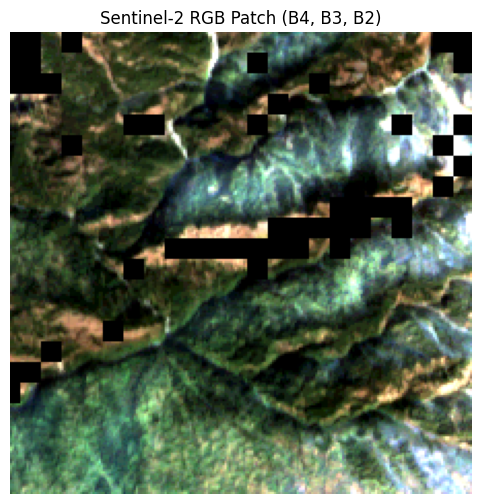

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

patch_dir = "/content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/valid_patches"

patch_file = "S2_forest_only-0000000000-0000000000_r3360_c1792.npz"
patch_path = os.path.join(patch_dir, patch_file)

with np.load(patch_path, allow_pickle=True) as data:
    image = data["image"].astype(np.float32)
    valid_mask = data["valid_mask"].astype(bool)

# Select Sentinel-2 RGB channels: B4, B3, B2
rgb_bands = image[[0, 1, 2]]

# A pixel is usable only if all three RGB values are finite
valid_rgb = valid_mask & np.all(np.isfinite(rgb_bands), axis=0)

rgb_image = np.zeros((224, 224, 3), dtype=np.float32)

for channel in range(3):
    band = rgb_bands[channel]
    values = band[valid_rgb]

    lower = np.percentile(values, 2)
    upper = np.percentile(values, 98)

    if upper <= lower:
        raise ValueError(f"Invalid scaling range for RGB channel {channel}")

    scaled = (band - lower) / (upper - lower)
    scaled = np.clip(scaled, 0, 1)

    # Invalid pixels are set to zero
    scaled[~valid_rgb] = 0

    rgb_image[:, :, channel] = scaled

print("RGB image shape:", rgb_image.shape)
print("Data type:", rgb_image.dtype)
print("Minimum:", float(rgb_image.min()))
print("Maximum:", float(rgb_image.max()))
print("All values finite:", bool(np.isfinite(rgb_image).all()))
print("Valid RGB pixel fraction:", round(float(valid_rgb.mean()), 4))

plt.figure(figsize=(6, 6))
plt.imshow(rgb_image)
plt.title("Sentinel-2 RGB Patch (B4, B3, B2)")
plt.axis("off")
plt.show()

In [ ]:
!pip -q install transformers

In [ ]:
import torch
from transformers import AutoImageProcessor, ViTModel

model_name = "google/vit-base-patch16-224-in21k"

processor = AutoImageProcessor.from_pretrained(model_name)
vit_model = ViTModel.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit_model = vit_model.to(device)
vit_model.eval()

print("Model:", model_name)
print("Device:", device)
print("Expected image size:", processor.size)
print("Normalization mean:", processor.image_mean)
print("Normalization standard deviation:", processor.image_std)
print("Hidden size:", vit_model.config.hidden_size)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model: google/vit-base-patch16-224-in21k
Device: cpu
Expected image size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Normalization mean: (0.5, 0.5, 0.5)
Normalization standard deviation: (0.5, 0.5, 0.5)
Hidden size: 768


In [ ]:
import numpy as np
import torch

# Check the prepared image
assert rgb_image.shape == (224, 224, 3)
assert np.isfinite(rgb_image).all()

# Convert the RGB image into the model's expected input format
inputs = processor(
    images=rgb_image,
    do_rescale=False,
    return_tensors="pt"
)

# Move input tensors to the same device as the model
inputs = {key: value.to(device) for key, value in inputs.items()}

print("Input tensor shape:", inputs["pixel_values"].shape)
print("Input tensor dtype:", inputs["pixel_values"].dtype)

# Extract features without training the model
with torch.no_grad():
    outputs = vit_model(**inputs)

# Use the CLS token as the image-level feature vector
features = outputs.last_hidden_state[:, 0, :]

print("Feature vector shape:", features.shape)
print("Feature vector size:", features.shape[-1])
print("All features finite:", bool(torch.isfinite(features).all()))
print("First 10 feature values:", features[0, :10].cpu().numpy())

Input tensor shape: torch.Size([1, 3, 224, 224])
Input tensor dtype: torch.float32
Feature vector shape: torch.Size([1, 768])
Feature vector size: 768
All features finite: True
First 10 feature values: [ 0.05392401  0.03134458  0.02194226 -0.20203787  0.12121831 -0.25308293
 -0.08414564 -0.11469387 -0.04273735  0.20654944]


In [ ]:
import torch
import numpy as np
import os
from transformers import AutoImageProcessor, ViTModel

# 1. Ensure model and processor are defined in the workspace
model_name = "google/vit-base-patch16-224-in21k"

if 'processor' not in locals() and 'processor' not in globals():
    print("Hugging Face processor not found in namespace. Loading...")
    processor = AutoImageProcessor.from_pretrained(model_name)

if 'vit_model' not in locals() and 'vit_model' not in globals():
    print("Hugging Face ViTModel not found in namespace. Loading...")
    vit_model = ViTModel.from_pretrained(model_name)

# 2. Ensure rgb_image is defined. If missing, reconstruct it from the sample patch.
if 'rgb_image' not in locals() and 'rgb_image' not in globals():
    print("rgb_image is not defined in namespace. Re-loading and preparing from sample patch...")
    patch_dir = "/content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/valid_patches"
    patch_file = "S2_forest_only-0000000000-0000000000_r3360_c1792.npz"
    patch_path = os.path.join(patch_dir, patch_file)

    with np.load(patch_path, allow_pickle=True) as data:
        image = data["image"].astype(np.float32)
        valid_mask = data["valid_mask"].astype(bool)

    # Select Sentinel-2 RGB channels: B4, B3, B2
    rgb_bands = image[[0, 1, 2]]
    valid_rgb = valid_mask & np.all(np.isfinite(rgb_bands), axis=0)

    rgb_image = np.zeros((224, 224, 3), dtype=np.float32)
    for channel in range(3):
        band = rgb_bands[channel]
        values = band[valid_rgb]
        lower = np.percentile(values, 2)
        upper = np.percentile(values, 98)
        scaled = (band - lower) / max(upper - lower, 1e-6)
        scaled = np.clip(scaled, 0, 1)
        scaled[~valid_rgb] = 0
        rgb_image[:, :, channel] = scaled

# Check that the prepared image is available
assert rgb_image.shape == (224, 224, 3)
assert np.isfinite(rgb_image).all()

# Prepare the input using the existing Hugging Face processor
inputs = processor(
    images=rgb_image,
    do_rescale=False,
    return_tensors="pt"
)

# Load the model onto the TPU (or Fallback to CPU/GPU)
try:
    # Typically, TPU is accessed via PyTorch XLA.
    # Here we attempt to send it to "tpu" or fallback to CPU/GPU device if "tpu" is not registered as a PyTorch backend.
    try:
        vit_model = vit_model.to("tpu")
        device = "tpu"
    except Exception:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        vit_model = vit_model.to(device)
        print(f"TPU backend unavailable, falling back to: {device}")

    vit_model.eval()
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = vit_model(**inputs)

    features = outputs.last_hidden_state[:, 0, :]

    print("Model device:", next(vit_model.parameters()).device)
    print("Input shape:", inputs["pixel_values"].shape)
    print("Feature shape:", features.shape)
    print("Features finite:", bool(torch.isfinite(features).all().item()))
    print("ViT execution test: SUCCESS")

except Exception as e:
    print("ViT execution test failed.")
    print("Error type:", type(e).__name__)
    print("Error details:", str(e)[:1500])

Model device: tpu:0
Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 768])
Features finite: True
ViT execution test: SUCCESS


In [ ]:
import os
import numpy as np
import torch
from PIL import Image
from transformers import AutoImageProcessor, ViTModel

# Paths
patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

# Load pretrained ViT
model_name = "google/vit-base-patch16-224-in21k"

processor = AutoImageProcessor.from_pretrained(model_name)
model = ViTModel.from_pretrained(model_name)

device = torch.device("tpu")
model = model.to(device)
model.eval()

# Select 4 patches from the filtered mapping
sample_patches = filtered_mapping["patch_file"].head(4).tolist()

batch_images = []

for filename in sample_patches:
    patch_path = os.path.join(patch_dir, filename)

    with np.load(patch_path, allow_pickle=True) as data:
        image = data["image"]
        valid_mask = data["valid_mask"]

    # Use RGB bands: B4, B3, B2
    rgb = image[[0, 1, 2]].transpose(1, 2, 0)

    # Normalize each band using its 2nd and 98th percentiles
    normalized = np.zeros_like(rgb, dtype=np.float32)

    for channel in range(3):
        valid_values = rgb[:, :, channel][valid_mask]
        low, high = np.percentile(valid_values, [2, 98])

        normalized[:, :, channel] = np.clip(
            (rgb[:, :, channel] - low) / (high - low + 1e-8),
            0, 1
        )

    # Set invalid pixels to zero
    normalized[~valid_mask] = 0

    batch_images.append(normalized)

# Prepare batch for ViT
inputs = processor(
    images=batch_images,
    do_rescale=False,
    return_tensors="pt"
)

pixel_values = inputs["pixel_values"].to(device)

# Extract CLS-token features
with torch.no_grad():
    outputs = model(pixel_values=pixel_values)
    features = outputs.last_hidden_state[:, 0, :]

print("Device:", device)
print("Input shape:", pixel_values.shape)
print("Feature shape:", features.shape)
print("All features finite:", torch.isfinite(features).all().item())
print("Small-batch ViT test: SUCCESS")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Device: tpu
Input shape: torch.Size([4, 3, 224, 224])
Feature shape: torch.Size([4, 768])
All features finite: True
Small-batch ViT test: SUCCESS


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from transformers import AutoImageProcessor, ViTModel

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

patch_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/valid_patches"
)

output_dir = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_Features"
)

checkpoint_dir = os.path.join(output_dir, "checkpoints")

os.makedirs(checkpoint_dir, exist_ok=True)

final_features_path = os.path.join(
    output_dir, "ViT_Satellite_Features.npz"
)

final_metadata_path = os.path.join(
    output_dir, "ViT_Satellite_Features_Metadata.csv"
)

BATCH_SIZE = 16
MODEL_NAME = "google/vit-base-patch16-224-in21k"

# Ensure the mapping exists
assert "filtered_mapping" in globals(), (
    "filtered_mapping is missing. Run the mapping-loading cell first."
)

assert len(filtered_mapping) > 0, "The filtered mapping is empty."

mapping_df = filtered_mapping.reset_index(drop=True).copy()

print("Total patches:", len(mapping_df))
print("Batch size:", BATCH_SIZE)
print("Total batches:", (len(mapping_df) + BATCH_SIZE - 1) // BATCH_SIZE)


# ============================================================
# 2. LOAD THE PRETRAINED VIT MODEL ON TPU
# ============================================================

device = torch.device("tpu")

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = ViTModel.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

print("Model loaded on:", device)


# ============================================================
# 3. PREPARE SATELLITE PATCHES
# ============================================================

def prepare_rgb_patch(patch_path):

    with np.load(patch_path, allow_pickle=True) as data:
        image = data["image"]
        valid_mask = data["valid_mask"].astype(bool)

    # Bands 0, 1, 2 correspond to B4, B3, B2
    rgb = image[[0, 1, 2]].transpose(1, 2, 0)

    normalized = np.zeros(rgb.shape, dtype=np.float32)

    # Normalize each band using valid pixels only
    for channel in range(3):

        values = rgb[:, :, channel][valid_mask]
        values = values[np.isfinite(values)]

        if len(values) == 0:
            raise ValueError(
                f"No finite valid pixels in {os.path.basename(patch_path)}"
            )

        low, high = np.percentile(values, [2, 98])

        if high <= low:
            raise ValueError(
                f"Invalid normalization range in "
                f"{os.path.basename(patch_path)}, channel {channel}"
            )

        band = rgb[:, :, channel]

        normalized[:, :, channel] = np.clip(
            (np.nan_to_num(
                band, nan=low, posinf=high, neginf=low
            ) - low) / (high - low),
            0,
            1
        )

    # Invalid pixels are set to zero
    normalized[~valid_mask] = 0

    return normalized


# ============================================================
# 4. EXTRACT FEATURES IN BATCHES WITH RESUMABLE CHECKPOINTS
# ============================================================

total_patches = len(mapping_df)
total_batches = (total_patches + BATCH_SIZE - 1) // BATCH_SIZE

for batch_number in range(total_batches):

    start = batch_number * BATCH_SIZE
    end = min(start + BATCH_SIZE, total_patches)

    batch_df = mapping_df.iloc[start:end]

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"batch_{batch_number:05d}.npz"
    )

    expected_files = batch_df["patch_file"].astype(str).to_numpy()

    # Skip only if the saved checkpoint matches this exact batch
    if os.path.exists(checkpoint_path):

        try:
            # Using allow_pickle=True to allow reading saved object arrays of strings
            with np.load(checkpoint_path, allow_pickle=True) as saved:
                saved_files = saved["patch_file"].astype(str)
                saved_features = saved["features"]

                checkpoint_valid = (
                    np.array_equal(saved_files, expected_files)
                    and saved_features.shape == (len(batch_df), 768)
                    and np.isfinite(saved_features).all()
                )

            if checkpoint_valid:
                print(
                    f"Batch {batch_number + 1}/{total_batches}: "
                    f"already complete; skipping."
                )
                continue

        except Exception:
            pass

        print(f"Rebuilding invalid checkpoint: batch {batch_number + 1}")

    # Prepare images for this batch
    images = []

    for filename in expected_files:

        patch_path = os.path.join(patch_dir, filename)

        if not os.path.isfile(patch_path):
            raise FileNotFoundError(
                f"Patch not found: {patch_path}"
            )

        images.append(prepare_rgb_patch(patch_path))

    # Convert images into the model's expected input format
    inputs = processor(
        images=images,
        do_rescale=False,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    # Extract the CLS-token feature vector
    with torch.no_grad():
        outputs = model(pixel_values=pixel_values)
        features = outputs.last_hidden_state[:, 0, :]

    # Transfer results from TPU to CPU for saving
    features_np = features.cpu().numpy().astype(np.float32)

    if features_np.shape != (len(batch_df), 768):
        raise ValueError(
            f"Unexpected feature shape: {features_np.shape}"
        )

    if not np.isfinite(features_np).all():
        raise ValueError(
            f"Non-finite features detected in batch {batch_number + 1}"
        )

    # Save the batch checkpoint
    temp_path = checkpoint_path + ".tmp.npz"

    np.savez_compressed(
        temp_path,
        features=features_np,
        patch_file=expected_files,
        cell_id=batch_df["cell_id"].astype(str).to_numpy()
    )

    os.replace(temp_path, checkpoint_path)

    print(
        f"Batch {batch_number + 1}/{total_batches} complete | "
        f"Patches {start + 1}-{end}/{total_patches} | "
        f"Features: {features_np.shape}"
    )


# ============================================================
# 5. COMBINE ALL CHECKPOINTS
# ============================================================

feature_batches = []
metadata_batches = []

for batch_number in range(total_batches):

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"batch_{batch_number:05d}.npz"
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Missing checkpoint: {checkpoint_path}. "
            "Rerun this cell to resume extraction."
        )

    # FIX: allow_pickle=True is required to load string metadata saved as NumPy objects
    with np.load(checkpoint_path, allow_pickle=True) as saved:
        features = saved["features"]
        patch_files = saved["patch_file"].astype(str)
        cell_ids = saved["cell_id"].astype(str)

    start = batch_number * BATCH_SIZE
    expected_files = (
        mapping_df.iloc[start:start + BATCH_SIZE]["patch_file"]
        .astype(str)
        .to_numpy()
    )

    if not np.array_equal(patch_files, expected_files):
        raise ValueError(
            f"Checkpoint order mismatch in batch {batch_number}. "
            "Check the mapping and checkpoint directory."
        )

    feature_batches.append(features)

    metadata_batches.append(
        pd.DataFrame({
            "patch_file": patch_files,
            "cell_id": cell_ids
        })
    )

all_features = np.concatenate(feature_batches, axis=0)
metadata_df = pd.concat(metadata_batches, ignore_index=True)

assert all_features.shape == (total_patches, 768)
assert len(metadata_df) == total_patches
assert np.isfinite(all_features).all()

# Save final feature matrix
np.savez_compressed(
    final_features_path,
    features=all_features,
    patch_file=metadata_df["patch_file"].to_numpy(),
    cell_id=metadata_df["cell_id"].to_numpy()
)

metadata_df.to_csv(final_metadata_path, index=False)

print("\n" + "=" * 55)
print("VIT FEATURE EXTRACTION COMPLETED SUCCESSFULLY")
print("=" * 55)
print("Device:", device)
print("Patches processed:", len(all_features))
print("Features per patch:", all_features.shape[1])
print("Final feature matrix:", all_features.shape)
print("All features finite:", np.isfinite(all_features).all())
print("Feature file:", final_features_path)
print("Metadata file:", final_metadata_path)
print("Checkpoints:", checkpoint_dir)

Total patches: 3986
Batch size: 16
Total batches: 250


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model loaded on: tpu
Batch 1/250: already complete; skipping.
Batch 2/250: already complete; skipping.
Batch 3/250: already complete; skipping.
Batch 4/250: already complete; skipping.
Batch 5/250: already complete; skipping.
Batch 6/250: already complete; skipping.
Batch 7/250: already complete; skipping.
Batch 8/250: already complete; skipping.
Batch 9/250: already complete; skipping.
Batch 10/250: already complete; skipping.
Batch 11/250: already complete; skipping.
Batch 12/250: already complete; skipping.
Batch 13/250: already complete; skipping.
Batch 14/250: already complete; skipping.
Batch 15/250: already complete; skipping.
Batch 16/250: already complete; skipping.
Batch 17/250: already complete; skipping.
Batch 18/250: already complete; skipping.
Batch 19/250: already complete; skipping.
Batch 20/250: already complete; skipping.
Batch 21/250: already complete; skipping.
Batch 22/250: already complete; skipping.
Batch 23/250: already complete; skipping.
Batch 24/250: already 

In [ ]:
import os
import numpy as np
import pandas as pd

feature_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_Features/ViT_Satellite_Features.npz"
)

metadata_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_Features/"
    "ViT_Satellite_Features_Metadata.csv"
)

# Load saved outputs (allow_pickle=True is required to parse string object arrays)
with np.load(feature_path, allow_pickle=True) as data:
    features = data["features"]
    patch_files = data["patch_file"].astype(str)
    cell_ids = data["cell_id"].astype(str)

metadata = pd.read_csv(metadata_path)

# Validate
print("Feature shape:", features.shape)
print("Metadata shape:", metadata.shape)
print("All features finite:", np.isfinite(features).all())
print("Unique patch files:", len(np.unique(patch_files)))
print("Unique grid cells:", len(np.unique(cell_ids)))
print("Patch order matches metadata:",
      np.array_equal(patch_files, metadata["patch_file"].astype(str).to_numpy()))
print("Cell IDs match metadata:",
      np.array_equal(cell_ids, metadata["cell_id"].astype(str).to_numpy()))

assert features.shape == (3986, 768)
assert len(metadata) == len(features)
assert np.isfinite(features).all()
assert np.array_equal(
    patch_files, metadata["patch_file"].astype(str).to_numpy()
)
assert np.array_equal(
    cell_ids, metadata["cell_id"].astype(str).to_numpy()
)

print("\nFeature files validated successfully!")

Feature shape: (3986, 768)
Metadata shape: (3986, 2)
All features finite: True
Unique patch files: 3986
Unique grid cells: 1159
Patch order matches metadata: True
Cell IDs match metadata: True

Feature files validated successfully!


In [ ]:
import numpy as np
import pandas as pd

# Load the existing file (no feature extraction needed)
with np.load(feature_path, allow_pickle=True) as data:
    features = data["features"].copy()
    patch_files = data["patch_file"].astype(str)
    cell_ids = data["cell_id"].astype(str)

# Overwrite the final file using explicit string dtypes
np.savez_compressed(
    feature_path,
    features=features,
    patch_file=np.asarray(patch_files, dtype=np.str_),
    cell_id=np.asarray(cell_ids, dtype=np.str_)
)

print("Final feature file corrected!")

Final feature file corrected!


In [ ]:
import numpy as np
import pandas as pd

feature_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_Features/ViT_Satellite_Features.npz"
)

output_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Satellite/ViT_Features/"
    "ViT_Features_By_Grid_Cell.csv"
)

# Load features safely
with np.load(feature_path, allow_pickle=False) as data:
    features = data["features"]
    cell_ids = data["cell_id"].astype(str)

print("Original feature matrix:", features.shape)

# Create a DataFrame containing cell IDs and feature vectors
feature_columns = [f"vit_{i}" for i in range(features.shape[1])]

features_df = pd.DataFrame(features, columns=feature_columns)
features_df.insert(0, "cell_id", cell_ids)

# Average features for patches belonging to the same grid cell
cell_features = (
    features_df
    .groupby("cell_id", as_index=False)[feature_columns]
    .mean()
)

# Save aggregated features
cell_features.to_csv(output_path, index=False)

print("\nAggregation completed!")
print("Unique grid cells:", cell_features["cell_id"].nunique())
print("Aggregated feature matrix:", cell_features.shape)
print("Missing values:", cell_features.isna().sum().sum())
print("Saved to:", output_path)

display(cell_features.head())

Original feature matrix: (3986, 768)

Aggregation completed!
Unique grid cells: 1159
Aggregated feature matrix: (1159, 769)
Missing values: 0
Saved to: /content/drive/MyDrive/FireWatchNet/Data/processed/Satellite/ViT_Features/ViT_Features_By_Grid_Cell.csv


,cell_id,vit_0,vit_1,vit_2,vit_3,vit_4,vit_5,vit_6,vit_7,vit_8,...,vit_758,vit_759,vit_760,vit_761,vit_762,vit_763,vit_764,vit_765,vit_766,vit_767
0,UK_210000_3325000,-0.007011,0.055307,-0.092831,-0.039266,-0.025636,-0.154646,0.023163,-0.051062,-0.067107,...,-0.111253,0.020443,0.008895,-0.094430,-0.021108,-0.001747,-0.070984,-0.318606,0.012769,0.135502
1,UK_210000_3330000,-0.056194,0.160343,0.053904,-0.118744,-0.076412,-0.012341,-0.088129,-0.143320,-0.100428,...,-0.186293,0.002318,0.105462,-0.191311,-0.139876,-0.168042,-0.081062,-0.315020,-0.107663,0.116751
2,UK_210000_3335000,-0.068995,0.143930,0.034899,-0.022605,-0.060799,-0.107622,-0.157591,-0.189973,-0.134602,...,-0.183706,-0.006927,0.033212,-0.100634,-0.052831,-0.193487,-0.073679,-0.348641,-0.099377,0.043758
3,UK_210000_3340000,-0.139982,0.110501,-0.050095,0.016304,-0.124332,-0.245687,-0.136949,-0.337781,-0.265817,...,-0.088052,-0.010439,-0.035172,0.049425,0.056602,-0.106086,0.009286,-0.303163,-0.160718,0.072754
4,UK_210000_3345000,-0.026329,-0.050541,-0.044145,-0.157773,-0.060105,-0.294356,-0.167090,-0.115097,-0.193065,...,-0.094433,0.027395,0.046317,-0.052987,-0.005562,0.002936,-0.086017,-0.248455,-0.027253,0.041888


In [ ]:
import pandas as pd
import os

labels_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/"
    "processed/Spatial/"
    "VIIRS_Grid_7Day_Forecast_Labels_5km_2023_2024.csv"
)

if not os.path.exists(labels_path):
    raise FileNotFoundError(f"Labels file not found: {labels_path}")

labels_df = pd.read_csv(labels_path)

print("Labels dataset shape:", labels_df.shape)
print("\nColumns:", labels_df.columns.tolist())
print("\nData types:")
print(labels_df.dtypes)

print("\nFirst five rows:")
display(labels_df.head())

print("\nDate range:")
print(labels_df["forecast_date"].min(), "to",
      labels_df["forecast_date"].max())

print("\nFire label distribution:")
print(labels_df["fire_next_7d"].value_counts(dropna=False))

print("\nUnique grid cells:", labels_df["cell_id"].nunique())

Labels dataset shape: (1616692, 3)

Columns: ['cell_id', 'forecast_date', 'fire_next_7d']

Data types:
cell_id          object
forecast_date    object
fire_next_7d      int64
dtype: object

First five rows:


,cell_id,forecast_date,fire_next_7d
0,UK_170000_3365000,2023-01-01,0
1,UK_170000_3365000,2023-01-02,0
2,UK_170000_3365000,2023-01-03,0
3,UK_170000_3365000,2023-01-04,0
4,UK_170000_3365000,2023-01-05,0



Date range:
2023-01-01 to 2024-12-24

Fire label distribution:
fire_next_7d
0    1550143
1      66549
Name: count, dtype: int64

Unique grid cells: 2233


In [ ]:
satellite_cells = set(cell_features["cell_id"].astype(str).unique())
label_cells = set(labels_df["cell_id"].astype(str).unique())

common_cells = satellite_cells & label_cells

print("Satellite cells:", len(satellite_cells))
print("Label cells:", len(label_cells))
print("Overlapping cells:", len(common_cells))
print("Satellite cells without labels:", len(satellite_cells - label_cells))
print("Label cells without satellite features:", len(label_cells - satellite_cells))
print("Label coverage by satellite features:",
      round(len(common_cells) / len(label_cells) * 100, 2), "%")

Satellite cells: 1159
Label cells: 2233
Overlapping cells: 1159
Satellite cells without labels: 0
Label cells without satellite features: 1074
Label coverage by satellite features: 51.9 %


In [ ]:
import pandas as pd
import os

mapping_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/processed/"
    "Satellite/Satellite_Patch_to_Grid_Mapping_Filtered.csv"
)

metadata_path = (
    "/content/drive/MyDrive/FireWatchNet/Data/processed/"
    "Satellite/ViT_Features/ViT_Satellite_Features_Metadata.csv"
)

for path in [mapping_path, metadata_path]:
    print("\nFILE:", os.path.basename(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found.")


FILE: Satellite_Patch_to_Grid_Mapping_Filtered.csv
Columns: ['patch_file', 'cell_id', 'nearest_centroid_distance_m', 'valid_fraction', 'patch_x_utm', 'patch_y_utm']


,patch_file,cell_id,nearest_centroid_distance_m,valid_fraction,patch_x_utm,patch_y_utm
0,S2_forest_only-0000000000-0000000000_r3360_c17...,UK_225000_3455000,2254.233781,0.910116,230435.323271,3.454870e+06
1,S2_forest_only-0000000000-0000000000_r3584_c17...,UK_230000_3450000,2126.268347,0.957151,230378.224894,3.452638e+06
2,S2_forest_only-0000000000-0000000000_r3808_c15...,UK_225000_3450000,2219.635199,0.881059,228402.211578,3.450456e+06



FILE: ViT_Satellite_Features_Metadata.csv
Columns: ['patch_file', 'cell_id']


,patch_file,cell_id
0,S2_forest_only-0000000000-0000000000_r3360_c17...,UK_225000_3455000
1,S2_forest_only-0000000000-0000000000_r3584_c17...,UK_230000_3450000
2,S2_forest_only-0000000000-0000000000_r3808_c15...,UK_225000_3450000
